# DSCI 552, Homework 5

Name: Ivan Sun  
GitHub Username: peterlololsss

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

### (a) Obtain Data

Get the Acute Inflammations Data Set

In [2]:
columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "inflammation", "nephritis"]
diagnosis = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, names=columns, encoding="utf-16", decimal=",")
for c in columns[1:]:
    diagnosis[c] = (diagnosis[c] == "yes").astype(int)

print("Data shape:", diagnosis.shape)
diagnosis.head()

Data shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

inflammation    40
nephritis       31
none            30
both            19
Name: count, dtype: int64
Number of leaves: 6
Training accuracy: 1.0


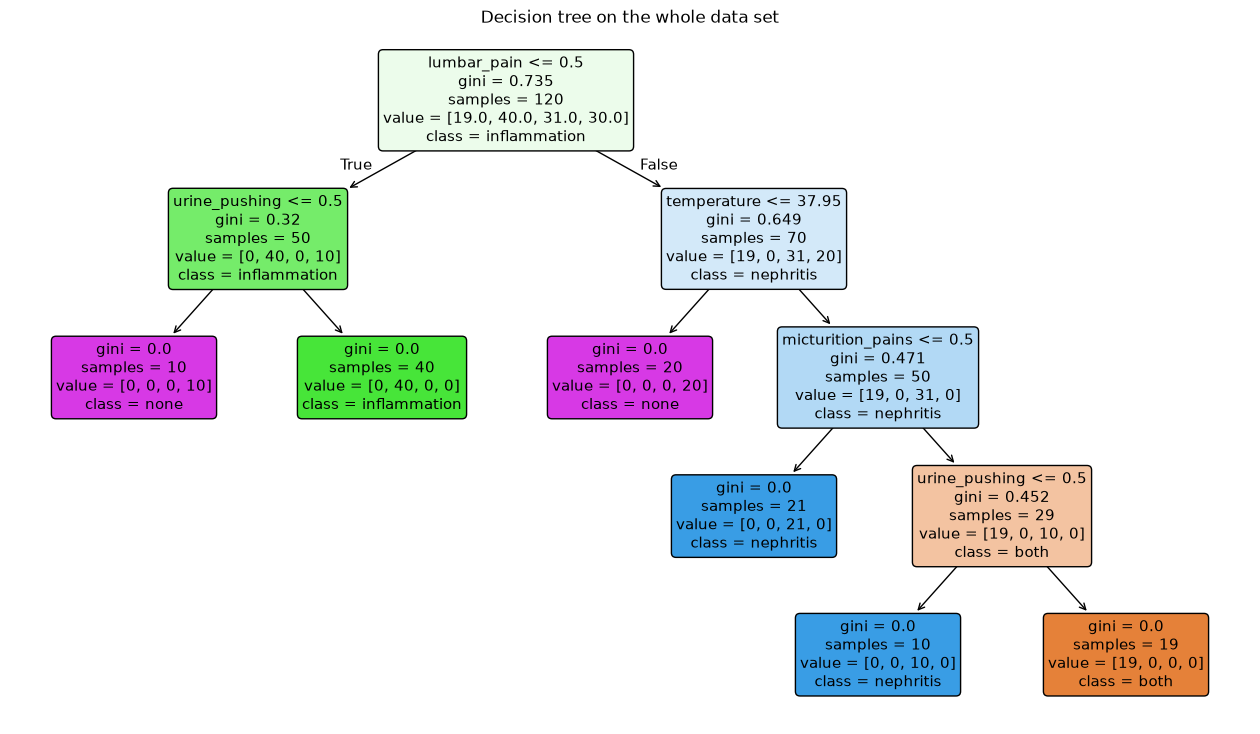

In [3]:
X = diagnosis[columns[:6]]
labels = {"00": "none", "10": "inflammation", "01": "nephritis", "11": "both"}
y = (diagnosis["inflammation"].astype(str) + diagnosis["nephritis"].astype(str)).map(labels)
print(y.value_counts())

tree = DecisionTreeClassifier(random_state=552)
tree.fit(X, y)
print("Number of leaves:", tree.get_n_leaves())
print("Training accuracy:", tree.score(X, y))

plt.figure(figsize=(16, 9))
plot_tree(tree, feature_names=list(X.columns), class_names=list(tree.classes_), filled=True, rounded=True)
plt.title("Decision tree on the whole data set")
plt.show()

I use the label powerset method, so each combination of the two labels (inflammation, nephritis) is one class and there are 4 classes. I think label powerset is the more relevant choice here. A patient can have both diseases, and one tree over the 4 combinations keeps this dependence and gives one set of rules for the joint diagnosis. All 4 combinations appear in the data (19 to 40 patients each), so no class is too small.

### (c) Convert the decision rules

In [4]:
def get_rules(tree, feature_names):
    t = tree.tree_
    rules = []

    def recurse(node, conditions):
        if t.feature[node] >= 0:
            name = feature_names[t.feature[node]]
            if name == "temperature":
                left = name + " <= " + str(round(t.threshold[node], 2))
                right = name + " > " + str(round(t.threshold[node], 2))
            else:
                left = name + " = no"
                right = name + " = yes"
            recurse(t.children_left[node], conditions + [left])
            recurse(t.children_right[node], conditions + [right])
        else:
            label = tree.classes_[np.argmax(t.value[node])]
            rules.append("IF " + " AND ".join(conditions) + " THEN " + label)

    recurse(0, [])
    return rules


for rule in get_rules(tree, list(X.columns)):
    print(rule)

IF lumbar_pain = no AND urine_pushing = no THEN none
IF lumbar_pain = no AND urine_pushing = yes THEN inflammation
IF lumbar_pain = yes AND temperature <= 37.95 THEN none
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both


### (d) Cost-complexity pruning

 ccp_alpha  leaves  train_accuracy  cv_accuracy
    0.0000       6          1.0000       0.9917
    0.0982       4          0.8417       0.8583
    0.1333       3          0.7583       0.7667
    0.1820       2          0.5917       0.6750
    0.2229       1          0.3333       0.4833
Chosen ccp_alpha: 0.0
Number of leaves: 6
Training accuracy: 1.0


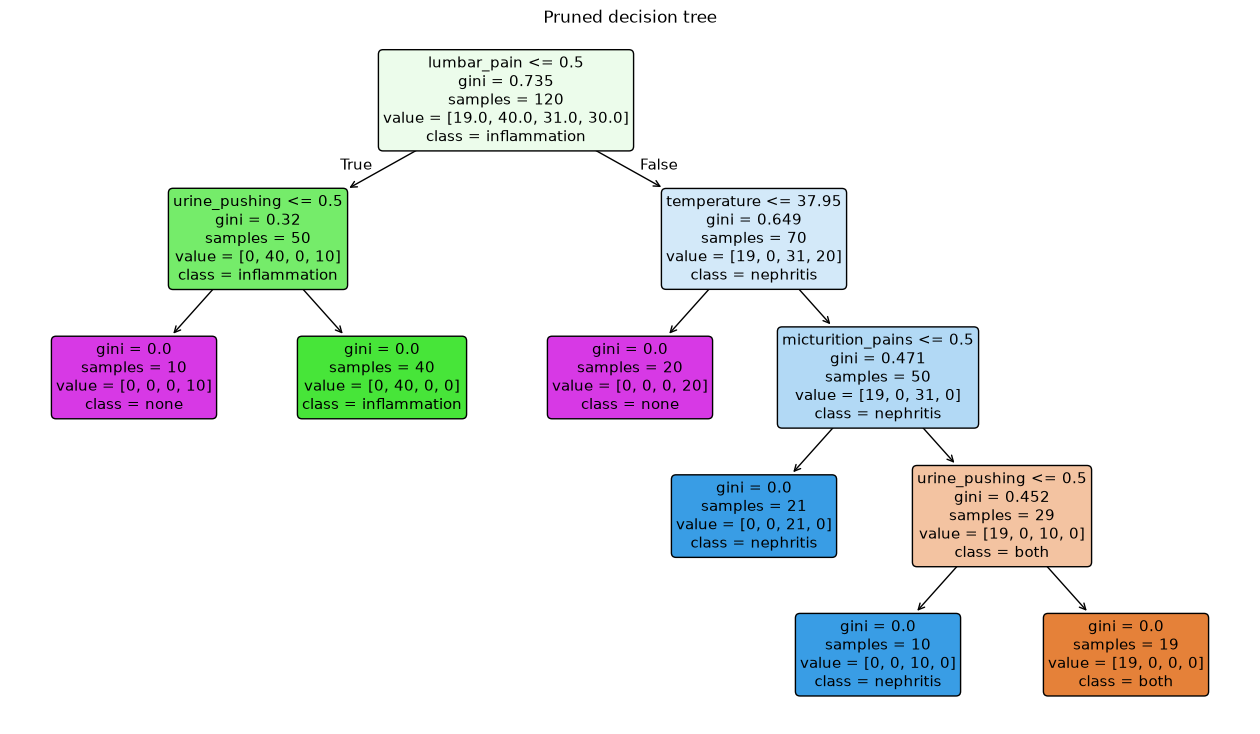

IF lumbar_pain = no AND urine_pushing = no THEN none
IF lumbar_pain = no AND urine_pushing = yes THEN inflammation
IF lumbar_pain = yes AND temperature <= 37.95 THEN none
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both


In [5]:
path = tree.cost_complexity_pruning_path(X, y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
results = []
for alpha in path.ccp_alphas:
    pruned = DecisionTreeClassifier(random_state=552, ccp_alpha=alpha)
    cv_accuracy = cross_val_score(pruned, X, y, cv=cv).mean()
    pruned.fit(X, y)
    results.append([alpha, pruned.get_n_leaves(), pruned.score(X, y), cv_accuracy])

prune_results = pd.DataFrame(results, columns=["ccp_alpha", "leaves", "train_accuracy", "cv_accuracy"])
print(prune_results.round(4).to_string(index=False))

best_alpha = prune_results[prune_results["cv_accuracy"] == prune_results["cv_accuracy"].max()]["ccp_alpha"].max()
print("Chosen ccp_alpha:", round(best_alpha, 4))

pruned_tree = DecisionTreeClassifier(random_state=552, ccp_alpha=best_alpha)
pruned_tree.fit(X, y)
print("Number of leaves:", pruned_tree.get_n_leaves())
print("Training accuracy:", pruned_tree.score(X, y))

plt.figure(figsize=(16, 9))
plot_tree(pruned_tree, feature_names=list(X.columns), class_names=list(pruned_tree.classes_), filled=True, rounded=True)
plt.title("Pruned decision tree")
plt.show()

for rule in get_rules(pruned_tree, list(X.columns)):
    print(rule)

I pick the largest $\alpha$ with the highest 5-fold CV accuracy. The CV accuracy is highest at $\alpha = 0$ (0.992), and the next value on the pruning path ($\alpha = 0.098$) cuts the tree from 6 to 4 leaves and drops the CV accuracy to 0.858. So the minimal tree is the full tree from (b). The 120 patients are perfectly separable by their symptoms, and every pruning step merges leaves with different diagnoses.

The 6 rules reduce to a short diagnosis:

- IF lumbar_pain = no AND urine_pushing = yes THEN inflammation
- IF lumbar_pain = yes AND temperature > 37.95 THEN nephritis, and also inflammation IF micturition_pains = yes AND urine_pushing = yes
- Otherwise none

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
names = [line.split()[1] for line in open("../data/communities.names") if line.startswith("@attribute")]
crime = pd.read_csv("../data/communities.data", header=None, names=names, na_values="?")
print("Data shape:", crime.shape)

train_data = crime.iloc[:1495]
test_data = crime.iloc[1495:]
print("Training set size:", len(train_data))
print("Test set size:", len(test_data))

Data shape: (1994, 128)
Training set size: 1495
Test set size: 499


### (b) Missing values

In [7]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
features = [c for c in names if c not in nonpredictive + [target]]
print("Number of features:", len(features))

missing = crime[features].isna().sum()
print(missing[missing > 0])

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(train_data[features]), columns=features)
X_test = pd.DataFrame(imputer.transform(test_data[features]), columns=features)
y_train = train_data[target].values
y_test = test_data[target].values
print("Missing values after imputation:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

Number of features: 122
OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64
Missing values after imputation: 0


I drop the 5 non-predictive columns (state, county, community, communityname, fold) and replace each missing value with the median of that feature in the training set.

### (c) Plot a correlation matrix

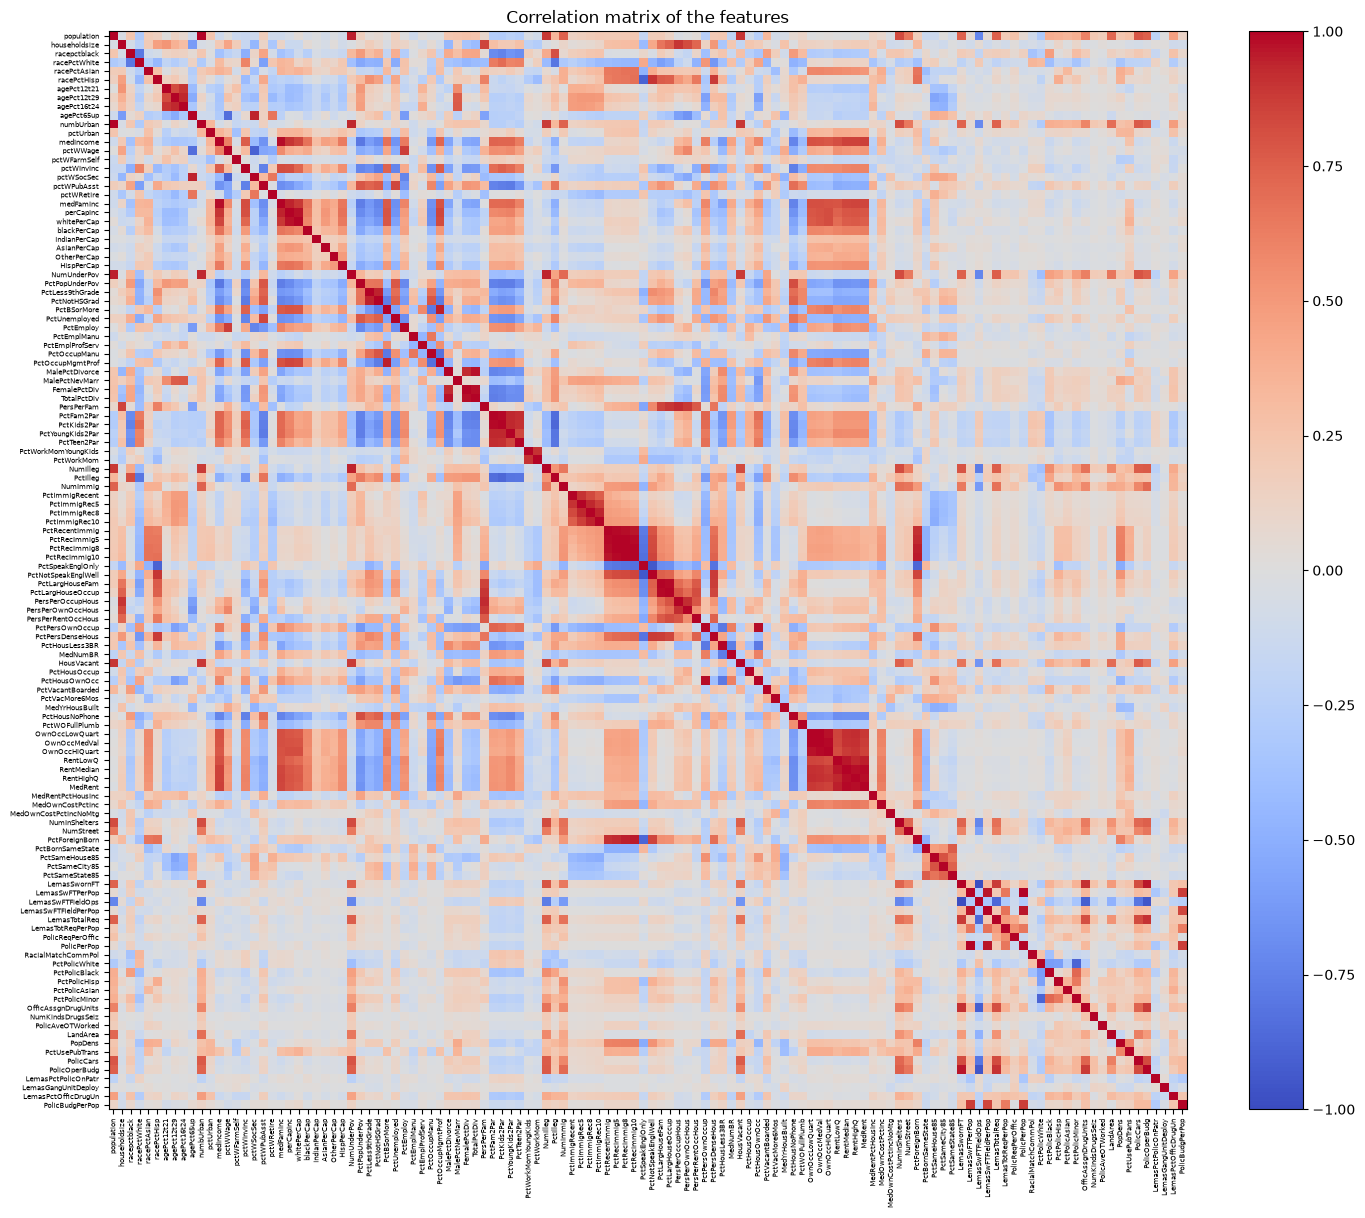

In [8]:
X_all = pd.concat([X_train, X_test], ignore_index=True)
corr = X_all.corr()

plt.figure(figsize=(16, 14))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(fraction=0.046)
plt.xticks(range(len(features)), features, rotation=90, fontsize=5)
plt.yticks(range(len(features)), features, fontsize=5)
plt.title("Correlation matrix of the features")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
cv_values = X_all.std() / X_all.mean()
cv_values = cv_values.sort_values(ascending=False)
print(cv_values.round(4).to_string())

PctPolicAsian            5.4478
NumStreet                4.4077
NumInShelters            3.4855
NumIlleg                 2.9942
NumImmig                 2.9005
LemasPctOfficDrugUn      2.5553
NumUnderPov              2.3050
population               2.2035
LemasSwornFT             2.0807
numbUrban                2.0017
HousVacant               1.9588
LandArea                 1.6780
racePctHisp              1.6143
PolicOperBudg            1.5629
PctNotSpeakEnglWell      1.4591
PctUsePubTrans           1.4167
racepctblack             1.4109
LemasTotalReq            1.3817
racePctAsian             1.3592
PctPolicHisp             1.3263
PctRecentImmig           1.3001
PctRecImmig5             1.2976
PctRecImmig10            1.2840
PctRecImmig8             1.2812
PctPersDenseHous         1.1272
OfficAssgnDrugUnits      1.0886
PolicCars                1.0876
PctForeignBorn           1.0723
PctVacantBoarded         1.0647
PctIlleg                 0.9198
PctHousNoPhone           0.9182
OwnOccMe

### (e) Scatter plots and box plots for highest CV features

Number of features: 11
Features with highest CV: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


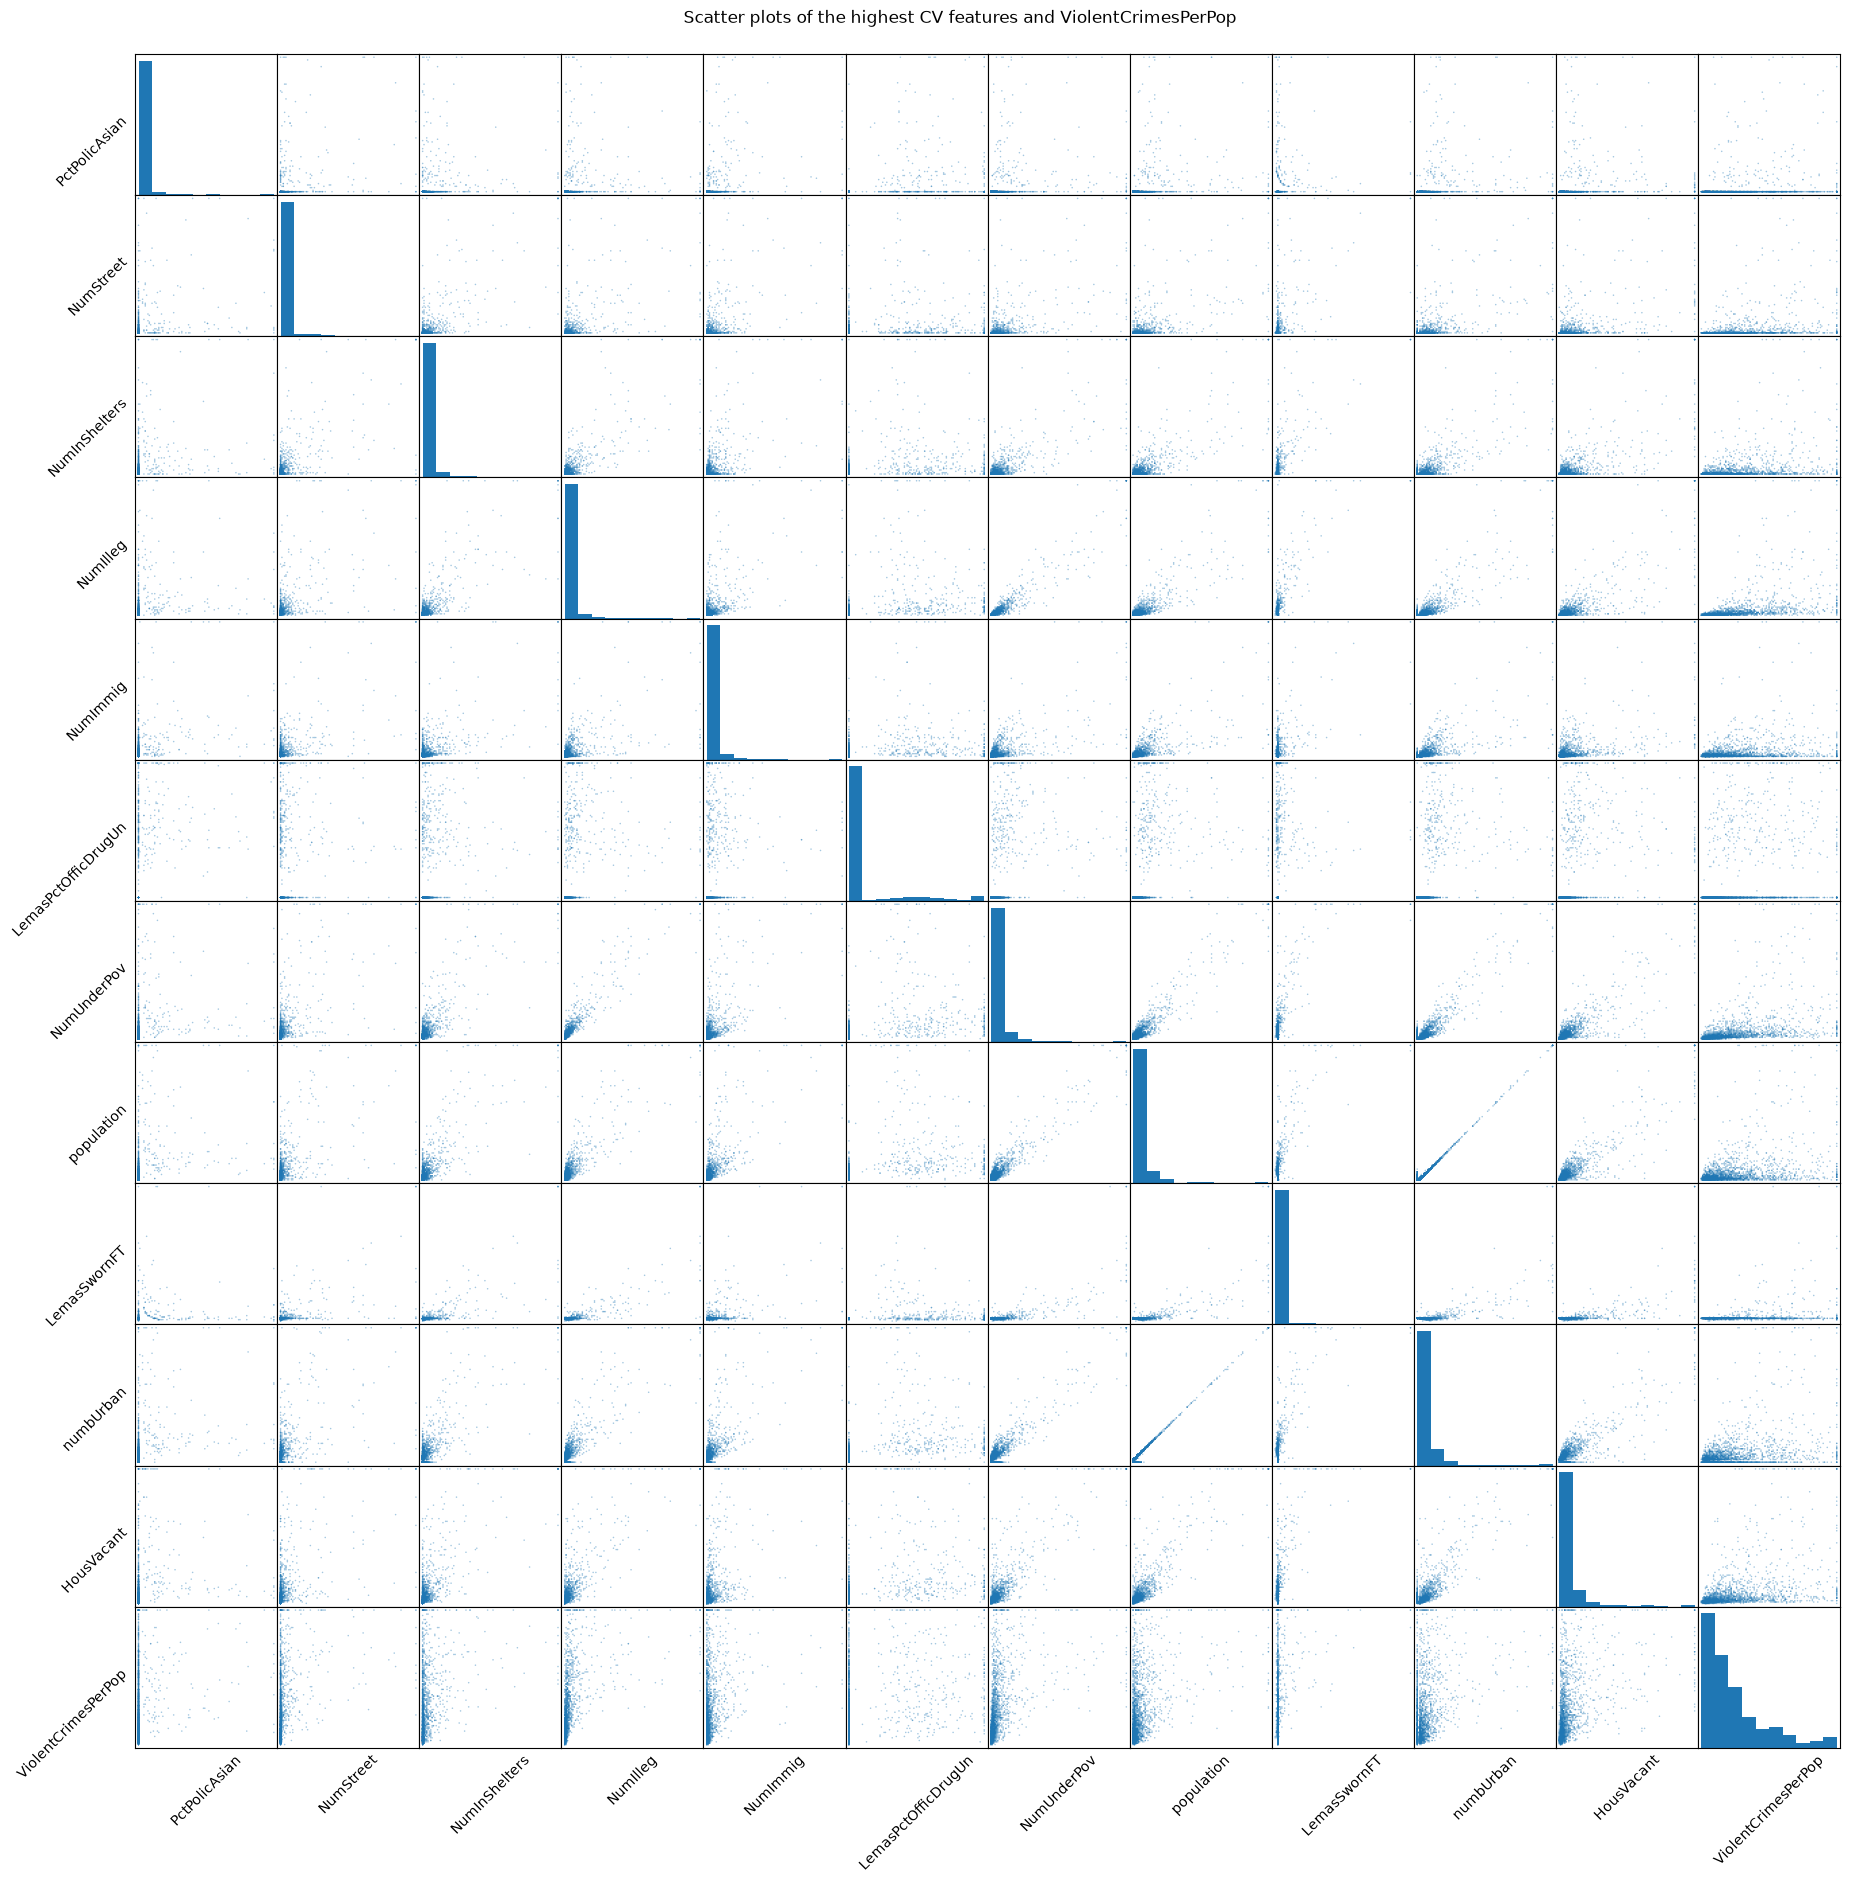

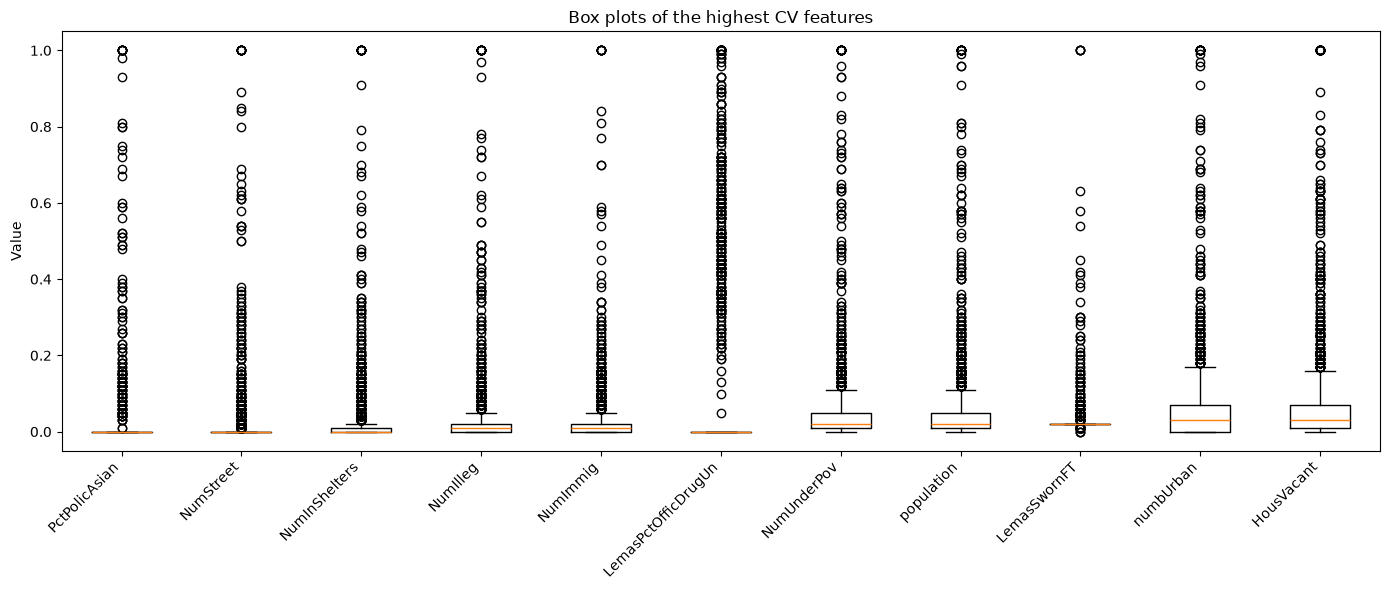

In [10]:
k = int(np.floor(np.sqrt(128)))
top_features = list(cv_values.index[:k])
print("Number of features:", k)
print("Features with highest CV:", top_features)

plot_data = X_all[top_features].copy()
plot_data[target] = np.concatenate([y_train, y_test])
axes = pd.plotting.scatter_matrix(plot_data, figsize=(22, 22), s=5, alpha=0.4, diagonal="hist")
for ax in axes.flatten():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.xaxis.label.set_rotation(45)
    ax.yaxis.label.set_rotation(45)
    ax.yaxis.label.set_ha("right")
plt.suptitle("Scatter plots of the highest CV features and " + target, y=0.9)
plt.show()

plt.figure(figsize=(14, 6))
plt.boxplot([X_all[f] for f in top_features], tick_labels=top_features)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.title("Box plots of the highest CV features")
plt.tight_layout()
plt.show()

No. In the panels against ViolentCrimesPerPop, communities with more violent crime tend to have larger NumIlleg, NumUnderPov and HousVacant, and the other features show no clear pattern. All 11 features are heavily right-skewed (the box plots show most values near 0 with many outliers), so a few large values drive any trend I see. A scatter plot shows the marginal relation between one feature and the response. Significance needs a fitted model with standard errors, and some of these features are almost collinear (population and numbUrban fall on a straight line), so a feature that looks related on its own may not be significant once the others are in the model.

### (f) Fit a linear model

In [11]:
ols = LinearRegression()
ols.fit(X_train, y_train)
ols_mse = mean_squared_error(y_test, ols.predict(X_test))
print("Test MSE (least squares):", round(ols_mse, 5))

Test MSE (least squares): 0.01797


### (g) Fit a ridge regression model

In [12]:
kf = KFold(n_splits=10, shuffle=True, random_state=552)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=kf, scoring="neg_mean_squared_error")
ridge.fit(X_train, y_train)
ridge_mse = mean_squared_error(y_test, ridge.predict(X_test))
print("Best lambda:", round(ridge.alpha_, 4))
print("Test MSE (ridge):", round(ridge_mse, 5))

Best lambda: 2.1544
Test MSE (ridge): 0.01753


### (h) Fit a LASSO model

In [13]:
lasso = LassoCV(cv=kf, max_iter=100000, random_state=552)
lasso.fit(X_train, y_train)
lasso_mse = mean_squared_error(y_test, lasso.predict(X_test))
lasso_selected = [f for f, b in zip(features, lasso.coef_) if b != 0]
print("Best lambda:", round(lasso.alpha_, 6))
print("Test MSE (LASSO):", round(lasso_mse, 5))
print("Number of selected variables:", len(lasso_selected))
print("Selected variables:", lasso_selected)

Best lambda: 8.2e-05
Test MSE (LASSO): 0.01769
Number of selected variables: 79
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', '

In [14]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

lasso_std = LassoCV(cv=kf, max_iter=100000, random_state=552)
lasso_std.fit(X_train_std, y_train)
lasso_std_mse = mean_squared_error(y_test, lasso_std.predict(X_test_std))
lasso_std_selected = [f for f, b in zip(features, lasso_std.coef_) if b != 0]
print("Best lambda:", round(lasso_std.alpha_, 6))
print("Test MSE (LASSO, standardized):", round(lasso_std_mse, 5))
print("Number of selected variables:", len(lasso_std_selected))
print("Selected variables:", lasso_std_selected)

Best lambda: 0.000619
Test MSE (LASSO, standardized): 0.01773
Number of selected variables: 76
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostP

The test MSE is 0.01769 with the original features (79 variables selected) and 0.01773 with standardized features (76 variables selected). The difference is less than 0.0001, and 75 variables are selected in both cases. The features are already normalized to [0, 1], so standardizing changes the penalty on each coefficient only a little and the two fits are almost the same.

### (i) Fit a PCR model

In [15]:
pcr = make_pipeline(StandardScaler(), PCA(), LinearRegression())
pcr_grid = GridSearchCV(pcr, {"pca__n_components": range(1, len(features) + 1)}, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
pcr_grid.fit(X_train, y_train)
pcr_mse = mean_squared_error(y_test, pcr_grid.predict(X_test))
print("Best M:", pcr_grid.best_params_["pca__n_components"])
print("Test MSE (PCR):", round(pcr_mse, 5))

Best M: 97
Test MSE (PCR): 0.01837


### (j) Fit a boosting tree

In [16]:
alpha_values = [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=552)
xgb_grid = GridSearchCV(xgb, {"reg_alpha": alpha_values}, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
xgb_grid.fit(X_train, y_train)

xgb_results = pd.DataFrame({"alpha": alpha_values, "cv_mse": -xgb_grid.cv_results_["mean_test_score"]})
print(xgb_results.round(5).to_string(index=False))

xgb_mse = mean_squared_error(y_test, xgb_grid.predict(X_test))
print("Best alpha:", xgb_grid.best_params_["reg_alpha"])
print("Test MSE (XGBoost):", round(xgb_mse, 5))

 alpha  cv_mse
 0.000 0.01955
 0.001 0.01955
 0.010 0.01946
 0.100 0.01967
 0.500 0.01918
 1.000 0.01917
 2.000 0.01908
 5.000 0.01998
10.000 0.02087
Best alpha: 2
Test MSE (XGBoost): 0.01614
